# Mental Accounting and Slack Spending
### Evidence of Discretionary Reallocation of Promotional Savings from the Dunnhumby Dataset

Replication notebook for the thesis by **Mwangi David Nguro** (Strathmore University, BBS Financial Economics). Running this notebook from top to bottom reproduces the commodity classification (Appendix A) and the tables, figures and reports used in Chapter 4, starting from the raw *Dunnhumby: The Complete Journey* files.

**How to run**

1. Download the dataset (it is not included in this repository; see the README, section *Getting the data*) and put the CSV files in `data/raw/`, or point `DATA_DIR` below at the folder that holds them.
2. Install the requirements: `pip install -r requirements.txt`.
3. Choose **Kernel ▸ Restart & Run All**. The pipeline contains no random numbers, so repeated runs give the same results.

All the code lives in `src/`; this notebook only calls it. Each step prints its report and also saves it as a text file next to its other outputs (`part_a_output/` for Part A, `part_b_output/` for Part B).

| Part | Step | Module | What it does |
|---|---|---|---|
| A | A1 | `part_a_checks` | Data checks and the commodity template |
| A | A2 | `part_a2_checks` | Follow-up checks and demographic recodes |
| A | A3 | `classify_commodities` | Necessity / Discretionary / Neutral / Exclude classification (Appendix A) |
| B | B1 | `b1_build_panel` | Household-week and household-trip panels |
| B | B2 | `b2_diagnostics` | Pre-estimation diagnostics (Chapter 4.4) |
| B | B3 | `b3_descriptives` | Descriptive statistics and figures (Chapter 4.5) |
| B | B4 | `b4_models` | Staged models and hypothesis tests (Chapters 4.6 and 4.7) |
| B | B5 | `b5_robustness`, `b5_forest_figure` | Robustness, falsification and mechanism checks (Chapter 4.8) |

## 0. Setup

In [1]:
import sys
from pathlib import Path

# The notebook must be opened from the repository root so that the `src` package can be found.
if not (Path.cwd() / "src").is_dir():
    raise RuntimeError("Open this notebook from the repository root (the folder that contains `src/`).")
sys.path.insert(0, str(Path.cwd()))

from src import (part_a_checks, part_a2_checks, classify_commodities, b1_build_panel, b2_diagnostics,
                 b3_descriptives, b4_models, b5_robustness, b5_forest_figure)
from src.config import Paths
from src.utils import check_raw_data, show_image

# ---------------------------------------------------------------------------------------------
# The only setting you may need to change: the folder with the Dunnhumby CSV files
# (transaction_data.csv, product.csv, hh_demographic.csv; coupon_redempt.csv is optional).
DATA_DIR = "data/raw/dunnhumby-the-complete-journey"
# ---------------------------------------------------------------------------------------------

paths = Paths.default(data_dir=DATA_DIR)
paths.make_dirs()
check_raw_data(paths.data_dir)        # stops with instructions if the files are missing
print("Raw data folder :", paths.data_dir)
print("Part A outputs  :", paths.show(paths.out_a))
print("Part B outputs  :", paths.show(paths.out_b))

Raw data folder : data/raw/dunnhumby-the-complete-journey
Part A outputs  : part_a_output
Part B outputs  : part_b_output


In [2]:
# Software versions used for this run (record these when you publish results)
import platform
import matplotlib, numpy, openpyxl, pandas, scipy, statsmodels

for name, mod in [("python", None), ("pandas", pandas), ("numpy", numpy), ("scipy", scipy), ("statsmodels", statsmodels),
                  ("matplotlib", matplotlib), ("openpyxl", openpyxl)]:
    print(f"{name:12s}", platform.python_version() if mod is None else mod.__version__)

python       3.11.7
pandas       2.1.4
numpy        1.26.4
scipy        1.11.4
statsmodels  0.14.0
matplotlib   3.8.0
openpyxl     3.0.10


## Part A. Data checks and commodity classification

Part A checks the raw data against the assumptions in Chapter 3 and builds the commodity classification described in Appendix A.

### A1. Data checks

Checks the panel dimensions, demographic coverage and discount fields, and builds a provisional household-week table.

Writes to `part_a_output/`: `part_a_report.txt`, `commodity_mapping_TEMPLATE.csv`, `attrition_table.csv`, `household_week_draft.csv`.

In [3]:
hw_draft = part_a_checks.run(paths)


0. COLUMN NAMES (use these exact names in your code and in Chapter 3)
transaction_data: ['household_key', 'basket_id', 'day', 'product_id', 'quantity', 'sales_value', 'store_id', 'retail_disc', 'trans_time', 'week_no', 'coupon_disc', 'coupon_match_disc']
product: ['product_id', 'manufacturer', 'department', 'brand', 'commodity_desc', 'sub_commodity_desc', 'curr_size_of_product']
hh_demographic: ['age_desc', 'marital_status_code', 'income_desc', 'homeowner_desc', 'hh_comp_desc', 'household_size_desc', 'kid_category_desc', 'household_key']

1. PANEL DIMENSIONS (proposal says 2,500 households and 104 weeks)
Rows in transaction_data: 2,595,732
Distinct households: 2500
WEEK_NO min / max: 1 / 102
Distinct weeks observed: 102
DAY min / max: 1 / 711 (~ days in window)
Distinct baskets (trips): 276,484

Active weeks per household:
count    2500.0
mean       49.6
std        25.5
min         1.0
25%        28.0
50%        50.0
75%        71.0
max       102.0
Share of households active in >= 50 

### A2. Follow-up checks

Tests whether `sales_value` is net or gross of discounts, and examines positive discounts, non-positive quantities, non-merchandise departments, the demographic subset, the activity filter, the demographic recodes and coupon sparseness.

Writes to `part_a_output/`: `part_a2_report.txt`, `demographics_clean.csv`.

In [4]:
part_a2_checks.run(paths)


A. IS sales_value NET OR GROSS OF retail_disc?  (shelf-price stability test)
Product-store-weeks with mixed discounted / undiscounted lines: 1,732
Median coefficient of variation, sales_value/quantity:            0.1933
Median coefficient of variation, (sales_value+savings)/quantity:  0.0
=> Adding savings back makes prices MORE stable: sales_value looks NET of retail_disc.
   Shelf (pre-discount) value = sales_value + savings. Customer paid ~ sales_value.
Always confirm against the dunnhumby data dictionary / user guide as well.

B. POSITIVE retail_disc VALUES (sign assumption fails for some lines)
Lines with retail_disc > 0: 36 (0.0014% of lines)
Sum of positive retail_disc:  8.53
Share of those lines with quantity <= 0: 0.833
Share of those lines with sales_value == 0: 0.472

By department (top 8):
            size   sum
department            
GROCERY       18  2.71
DRUG GM       10  1.04
MEAT           3  0.00
MEAT-PCKGD     3  3.99
FLORAL         1  0.00
PRODUCE        1  0.79

S

### A3. Commodity classification

Applies the classification rules in `src/classify_commodities.py` (the scope, needs and indulgence tests of Appendix A) to every department and commodity in the template.

Writes to `part_a_output/`: `commodity_mapping_CLASSIFIED.csv`.

In [5]:
classified = classify_commodities.run(paths)

Rows classified: 360   unmapped: 0

Share of template sales_value excluded as non-merchandise: 0.091

Commodity counts and share of MERCHANDISE sales (these shares are for the 360 commodities, all households):
               commodities       sales  share_of_merch
category                                              
Discretionary           68  1763157.87           0.241
Exclude                 49   729723.79             NaN
Necessity              159  4692014.62           0.640
Neutral                 84   872566.80           0.119

Discretionary definitions (share of merchandise sales):
  narrow_disc  0.171
  main_disc    0.196
  broad_disc   0.241

Discretionary groups (share of merchandise sales):
group                  disc_tier
sugary_drinks          core         0.0447
alcohol                core         0.0360
sweet_bakery           core         0.0275
snacks_other           extended     0.0246
salty_snacks           core         0.0202
frozen_desserts        core         0.01

## Part B. Panel construction, diagnostics, estimation and robustness

### B1. Build the analysis panels

Merges transactions, products and the classification; removes non-merchandise lines and lines with quantity of zero or less; builds the household-week panel; applies the sample filters; and builds the household-trip panel.

* `min_active_weeks`: households observed in fewer weeks are dropped.
* `outlier_q`: household-weeks with total spend above this quantile (bulk purchases) are dropped.

Writes to `part_b_output/`: `hw_all.csv`, `hw_main.csv`, `trips_main.csv`, `attrition_table.csv`, `variable_dictionary.csv`, `part_b1_report.txt`.

In [6]:
panels = b1_build_panel.run(paths, min_active_weeks=10, outlier_q=0.999)


1. LOAD AND MERGE (transactions + product + classification)
Transaction lines: 2,595,732   lines with no valid classification: 0

2. LINE-LEVEL CLEANING
Non-merchandise lines (category = Exclude): 45,904 (1.8% of lines, 9.1% of sales_value)
Merchandise lines with quantity <= 0: 6,362 (sales_value on them: 19.18) -> dropped
Merchandise lines kept: 2,543,466
Lines with positive RETAIL_DISC: 6 (total 4.25) -> savings floored at zero

3. HOUSEHOLD-WEEK AGGREGATION
Household-weeks with merchandise spend > 0: 120,993  households: 2500
Check: Necessity + Discretionary(broad) + Neutral = total_spend, max abs gap = 1.14e-13
Check: main <= broad discretionary spend: True

4. SAMPLE FILTERS AND ATTRITION
                                                                               step  households  household_weeks  baskets
                                                 All households in transaction_data        2500           123976   276484
Merchandise lines only (non-merchandise and quantity

### B2. Pre-estimation diagnostics (Chapter 4.4)

Panel structure, distributions and transformations, multicollinearity, unit roots, poolability and model choice (F, Breusch-Pagan LM, Mundlak), serial correlation, heteroskedasticity, cross-sectional dependence, standard-error choice and representativeness.

Writes to `part_b_output/`: `diagnostics_table.csv`, `representativeness_table.csv`, `b2_distributions.png`, `part_b2_report.txt`.


1. PANEL STRUCTURE
Observations (household-weeks): 55,180   households N = 801   distinct weeks T = 102   regressors K = 3
Observations per household: min 21, p25 58, median 71, p75 81, max 101
Balance: 55,180 of 81,702 possible household-weeks observed (67.5%) -> unbalanced panel
Households with at least one gap between observed weeks: 97.5%; median number of gaps per household: 14
Missing values in model variables: 0
Decision: unbalanced panel is acceptable for fixed-effects estimation (within estimator needs no balance); tests below use unbalanced-panel formulas.

2. DISTRIBUTIONS AND TRANSFORMATIONS
        variable  mean    sd  skewness  excess_kurtosis  share_zero   p1    p99
      disc_spend 14.10 16.25      2.58            11.91       0.143 0.00  74.11
asinh_disc_spend  2.61  1.42     -0.57            -0.63       0.143 0.00   5.00
      disc_share 21.26 20.17      1.65             3.28       0.143 0.00 100.00
     total_spend 72.78 64.31      1.60             3.28       0.000 

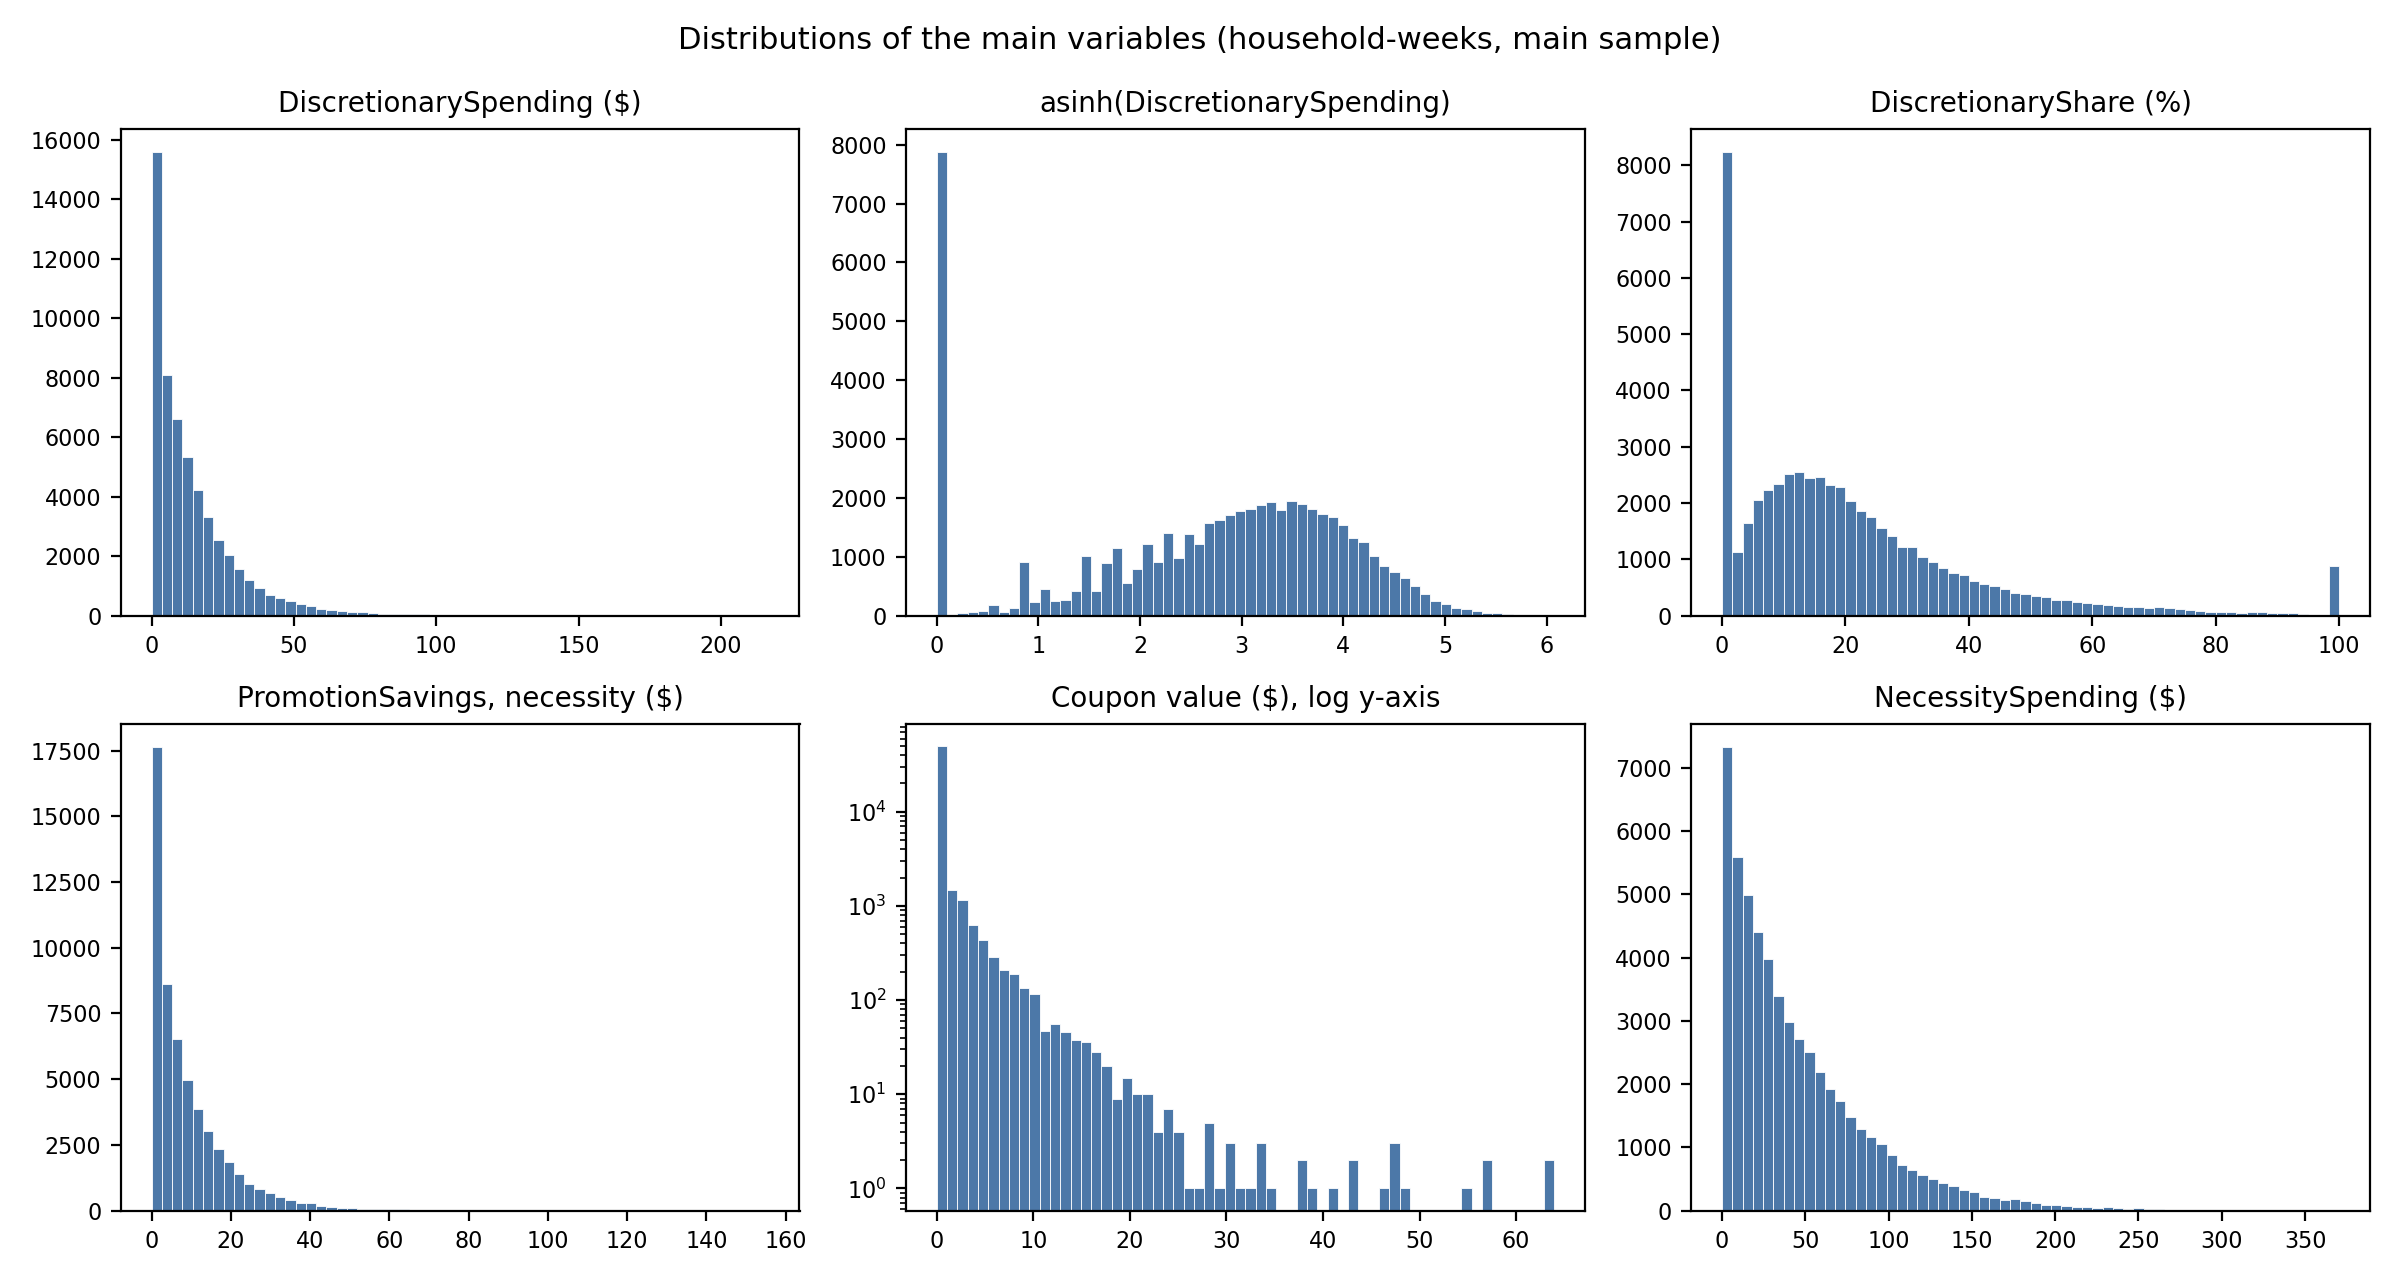

In [7]:
diagnostics = b2_diagnostics.run(paths)
show_image(paths.out_b / "b2_distributions.png", width=900)

### B3. Descriptive statistics and figures (Chapter 4.5)

Writes to `part_b_output/`: `b3_tables.xlsx` and one `b3_*.csv` per table, `b3_fig_weekly.png`, `b3_fig_composition.png`, `part_b3_report.txt`.


1. SUMMARY STATISTICS (household-week level, main sample)
                                   Variable     N  Mean    SD  Min   P25  Median    P75    Max
                  DiscretionarySpending ($) 55180 14.10 16.25  0.0  2.99    9.27  19.73 216.76
                     DiscretionaryShare (%) 55180 21.26 20.17  0.0  7.23   16.65  29.10 100.00
                      NecessitySpending ($) 55180 46.29 44.58  0.0 13.36   33.11  65.86 370.47
                       Neutral spending ($) 55180  9.08 12.38  0.0  0.00    4.91  12.54 170.26
                Total merchandise spend ($) 55180 72.78 64.31  0.2 24.92   54.62 101.91 439.67
      PromotionSavings, necessity items ($) 55180  9.06 10.57  0.0  1.68    5.66  12.78 155.72
            PromotionSavings, all items ($) 55180 13.44 14.13  0.0  3.42    9.24  18.86 172.17
Necessity markdown depth (% of shelf value) 52914 15.47  9.70  0.0  8.85   14.49  20.98  74.35
                           Coupon value ($) 55180  0.47  1.95  0.0  0.00    0.00   0.0

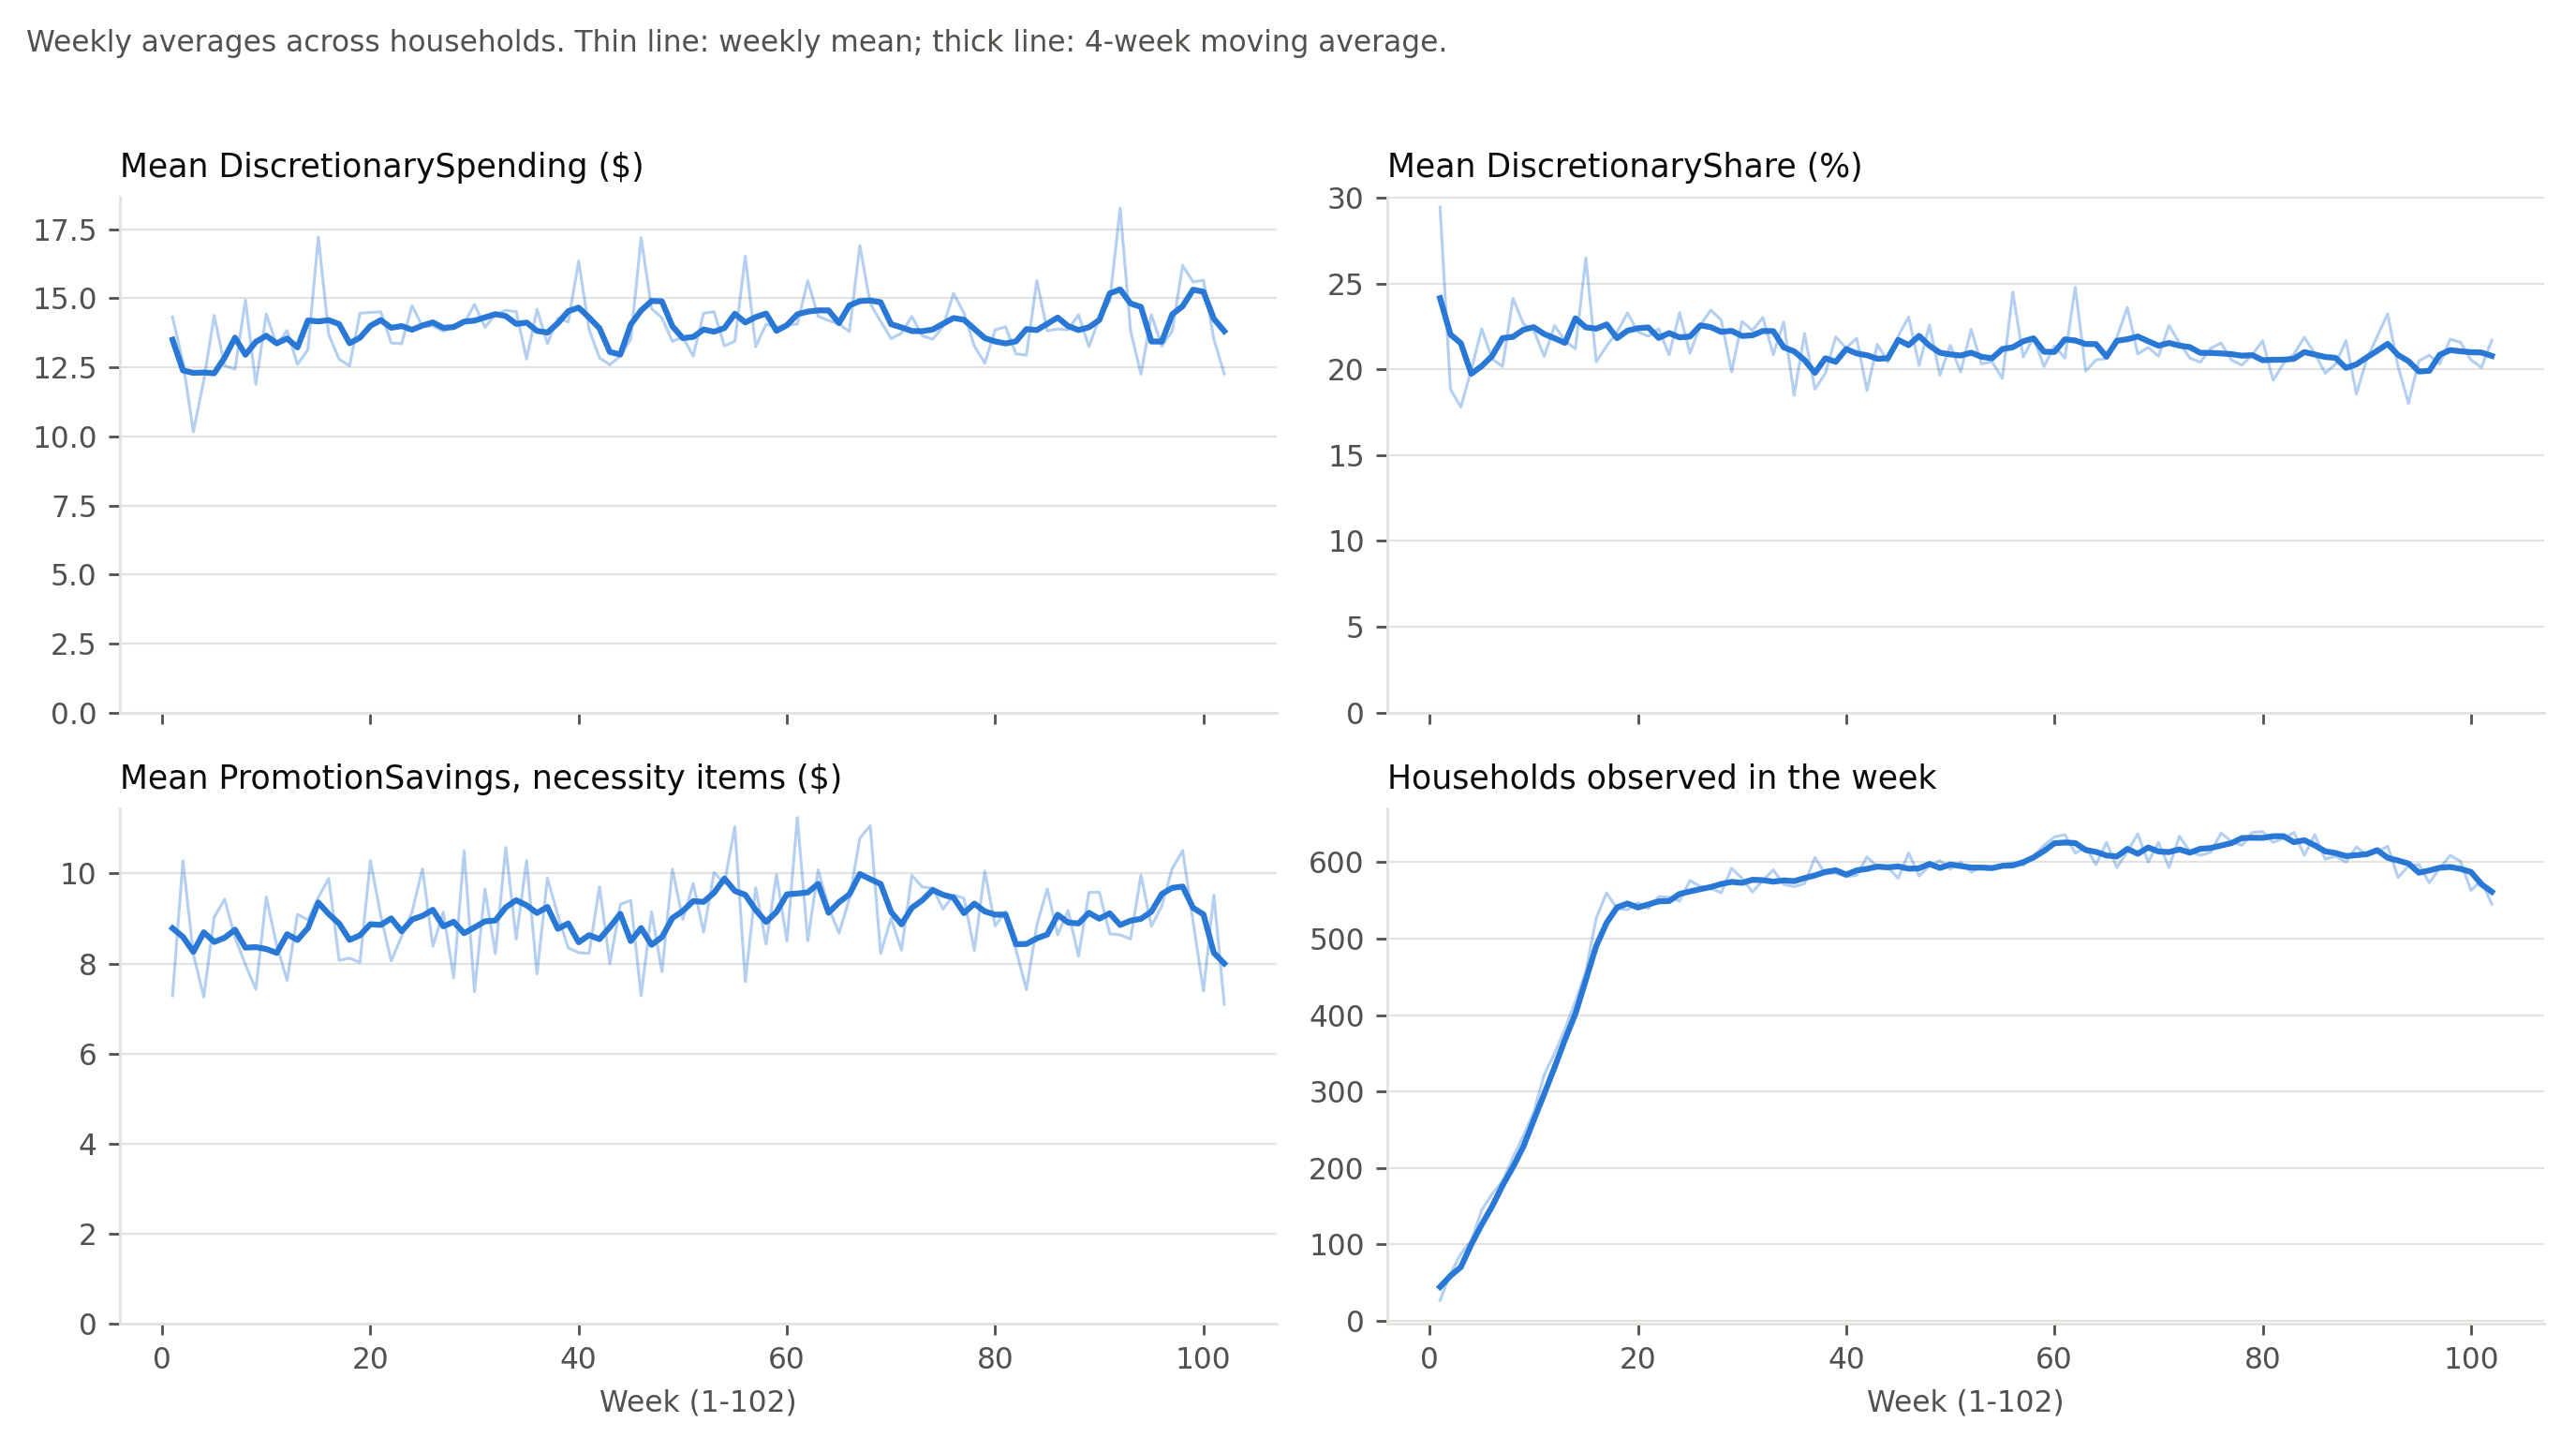

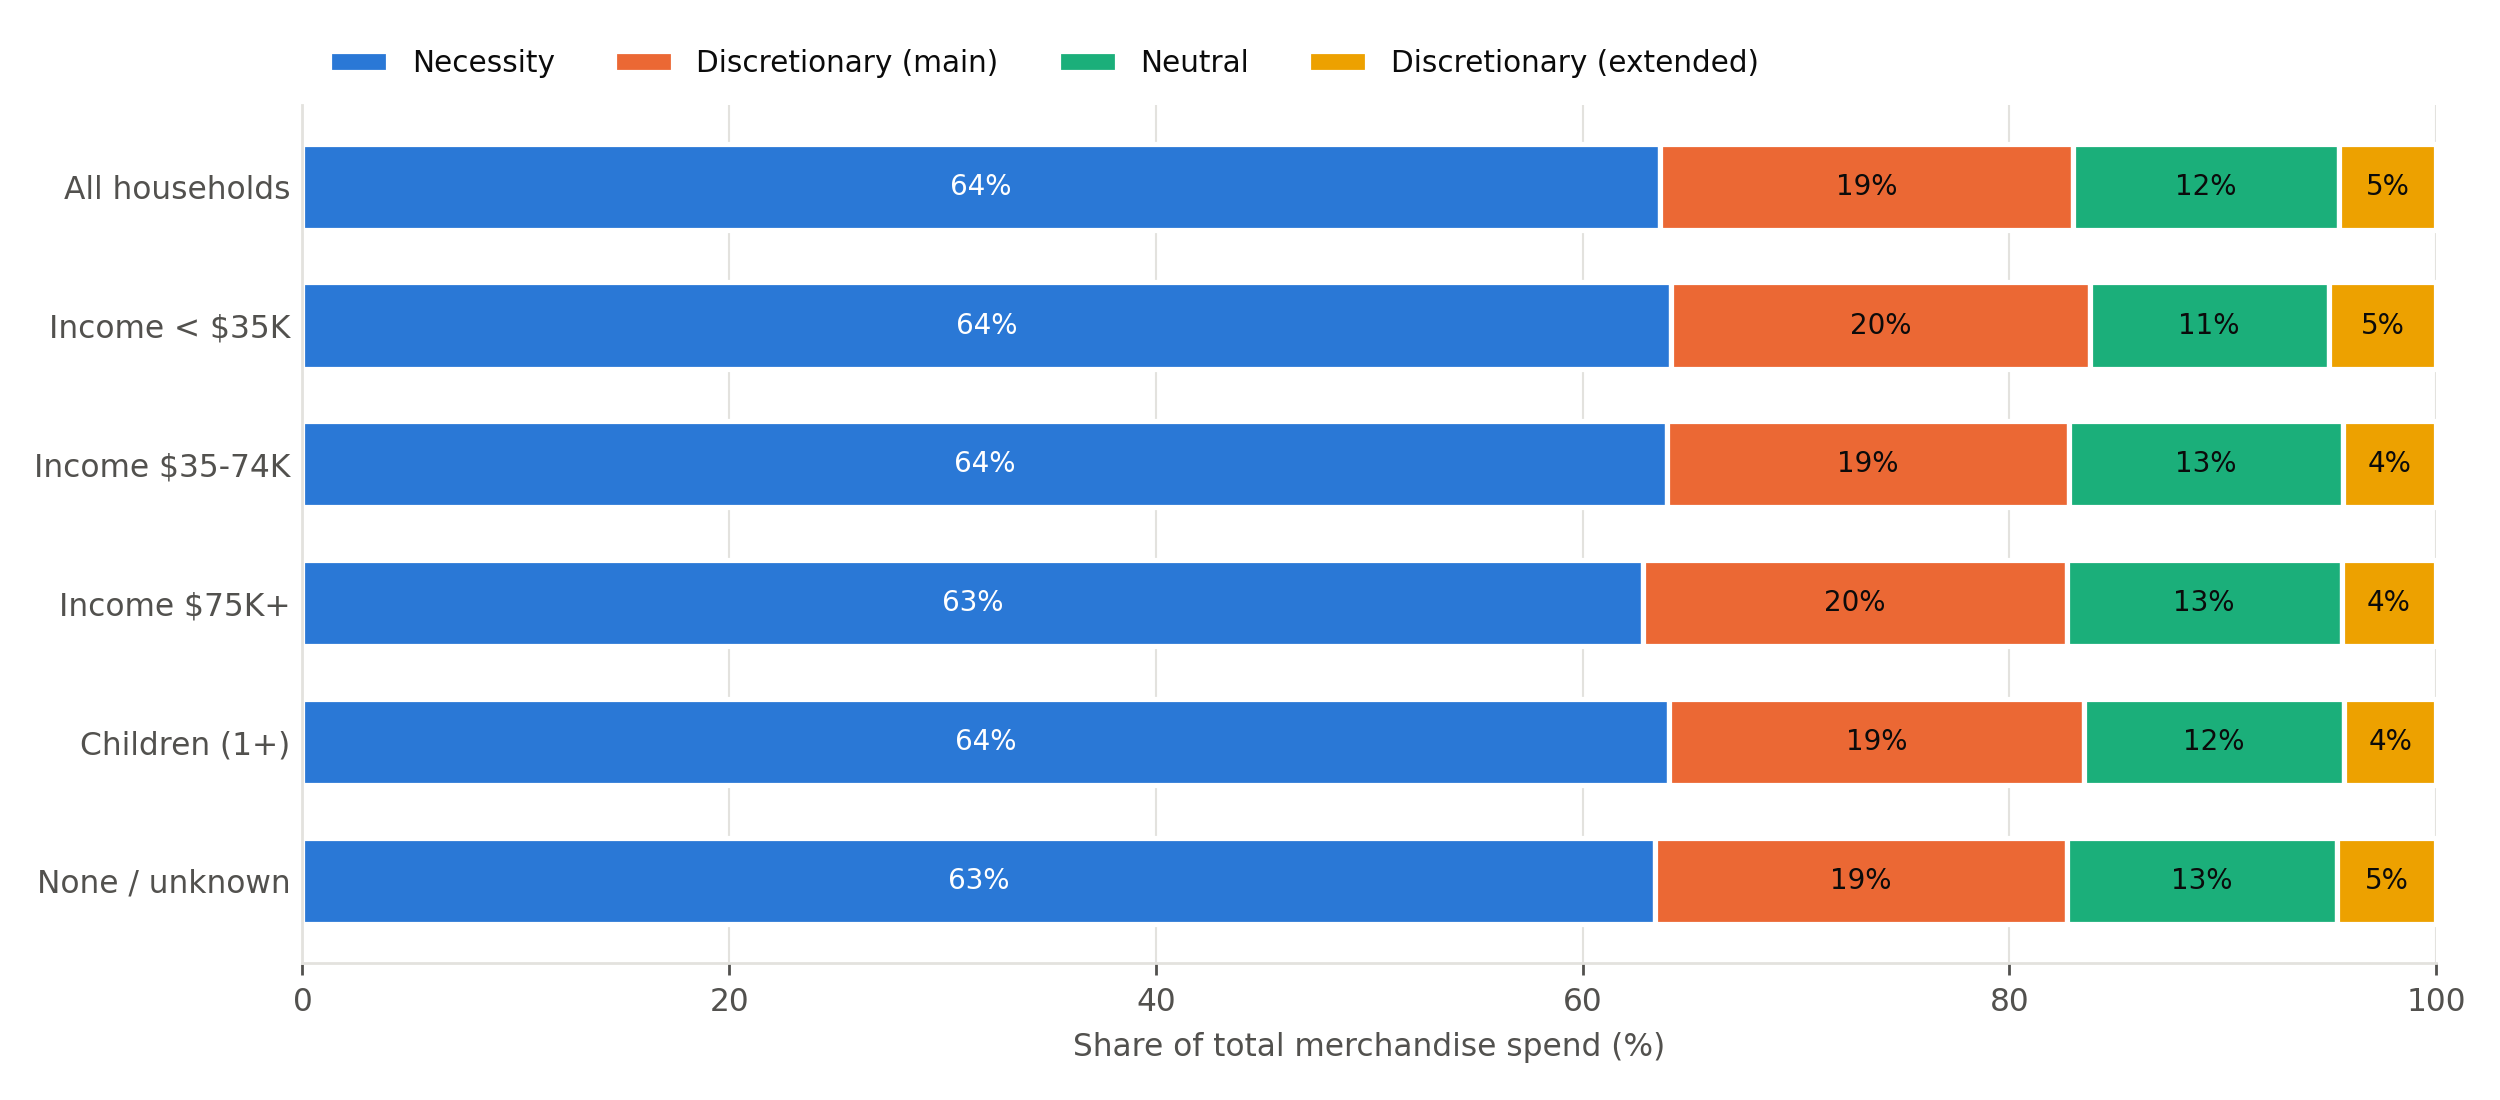

In [8]:
descriptives = b3_descriptives.run(paths)
show_image(paths.out_b / "b3_fig_weekly.png", width=900)
show_image(paths.out_b / "b3_fig_composition.png", width=900)

### B4. Staged models and hypothesis tests (Chapters 4.6 and 4.7)

Pooled, pooled with controls, Mundlak correlated random effects and two-way fixed-effects models for both outcomes (preferred model: two-way fixed effects, household-clustered standard errors); one-sided tests of H1, H2 and H3; inference check; effect sizes.

Writes to `part_b_output/`: `b4_tables.xlsx` and one `b4_*.csv` per table, `b4_fig_stability.png`, `b4_fig_binned.png`, `part_b4_report.txt`.

Main sample: 55,180 household-weeks, 801 households, 102 weeks

MODEL 1: DISCRETIONARYSPENDING ($)  -  coefficients with household-clustered SEs in parentheses (* p<0.10, ** p<0.05, *** p<0.01)
                                                Variable (1) Pooled, no controls (a) Pooled + controls (b) Mundlak CRE (c) Two-way FE
                   PromotionSavings (necessity items, $)                0.532***              -0.051**          -0.018         -0.018
                                                                         (0.022)               (0.026)         (0.014)        (0.014)
                                        Coupon value ($)                0.473***               0.247**        0.197***       0.197***
                                                                         (0.126)               (0.116)         (0.074)        (0.074)
                                   NecessitySpending ($)                                      0.181***        0.162***       0.162***
  

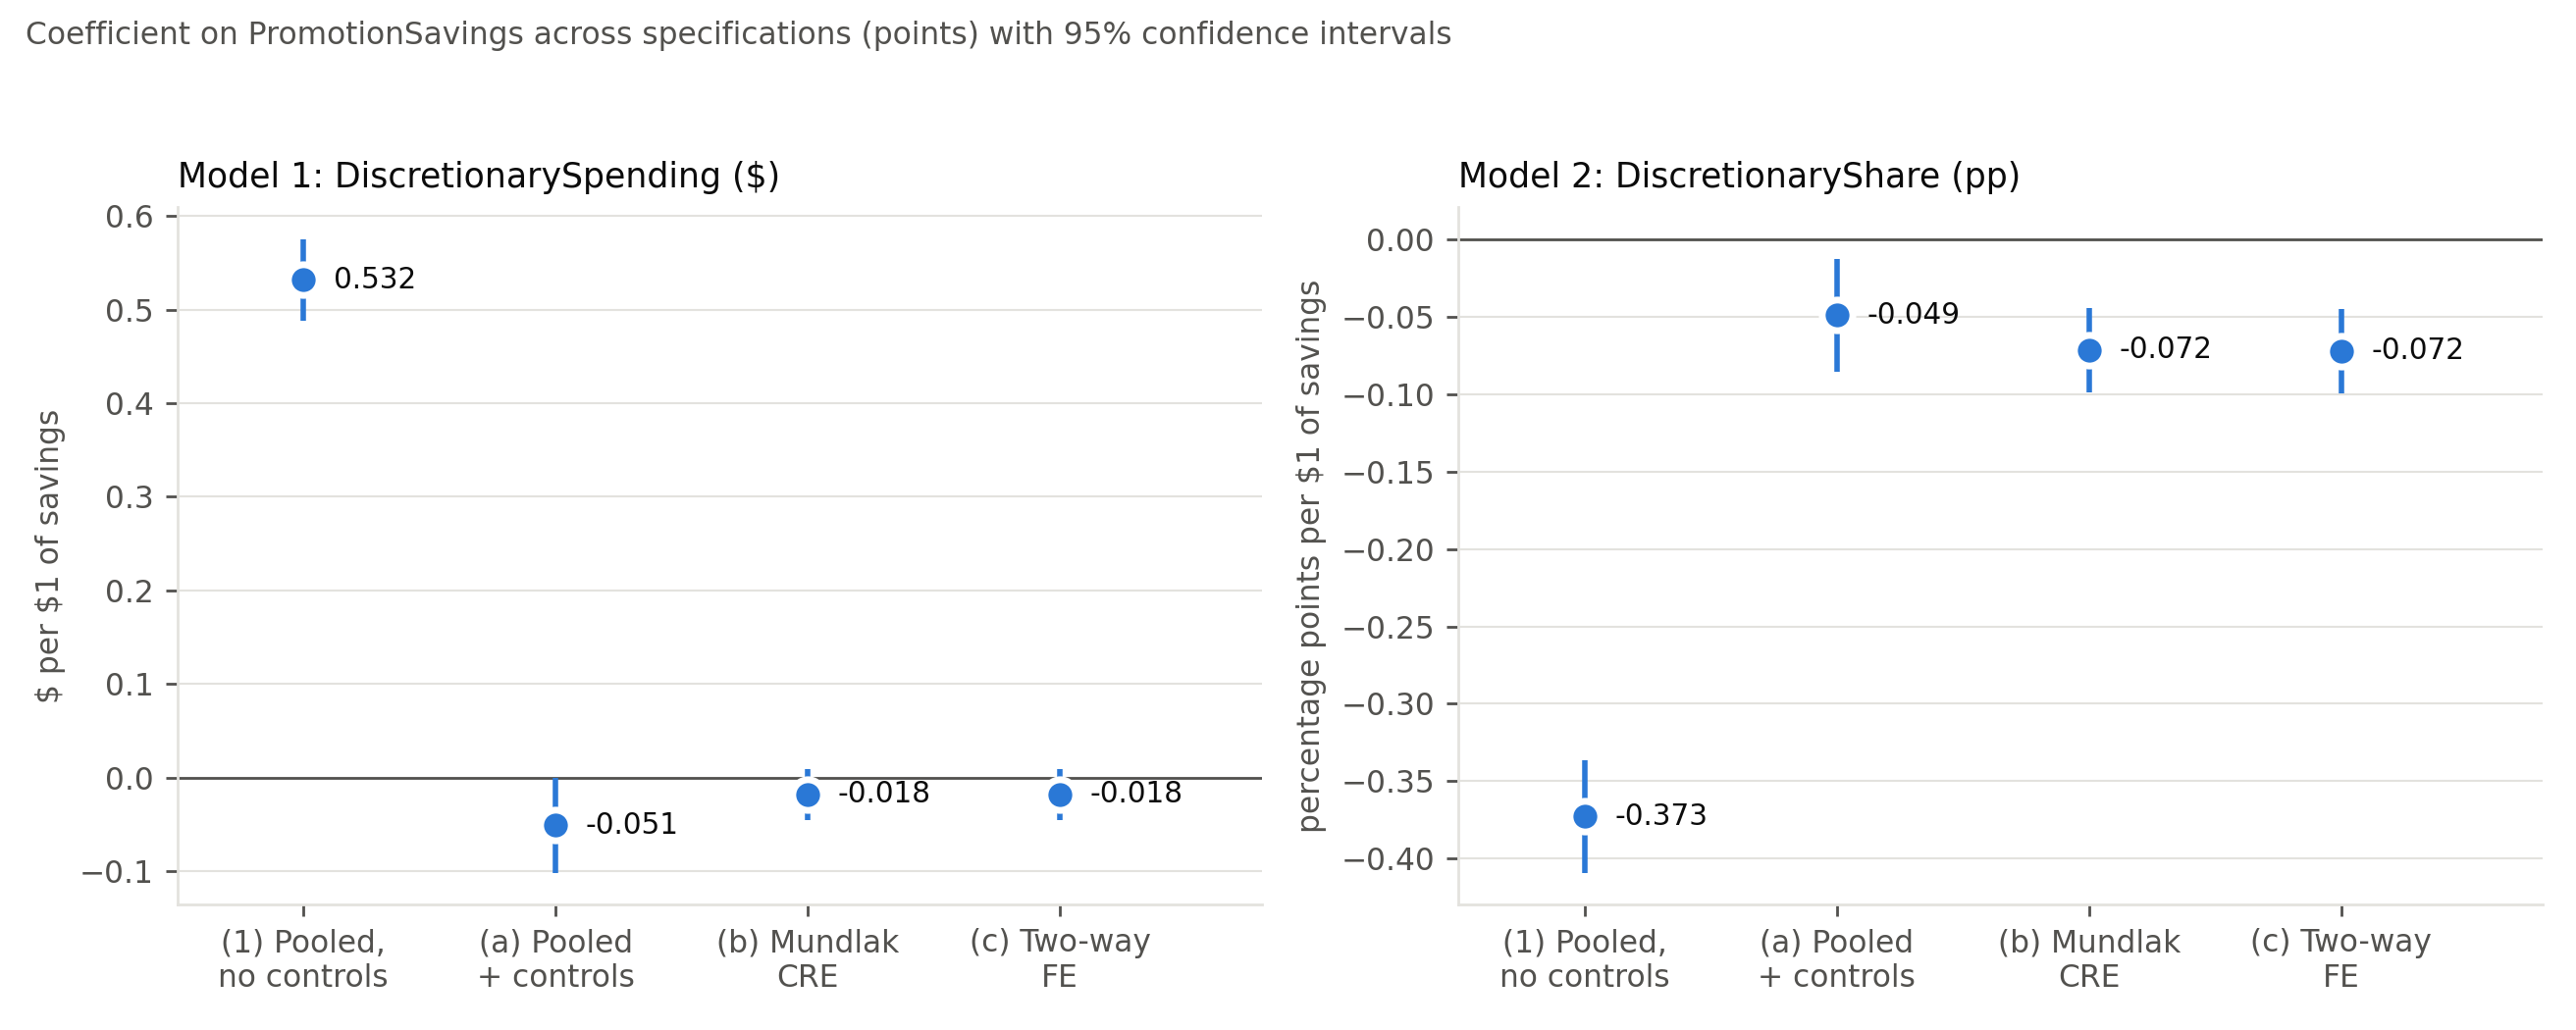

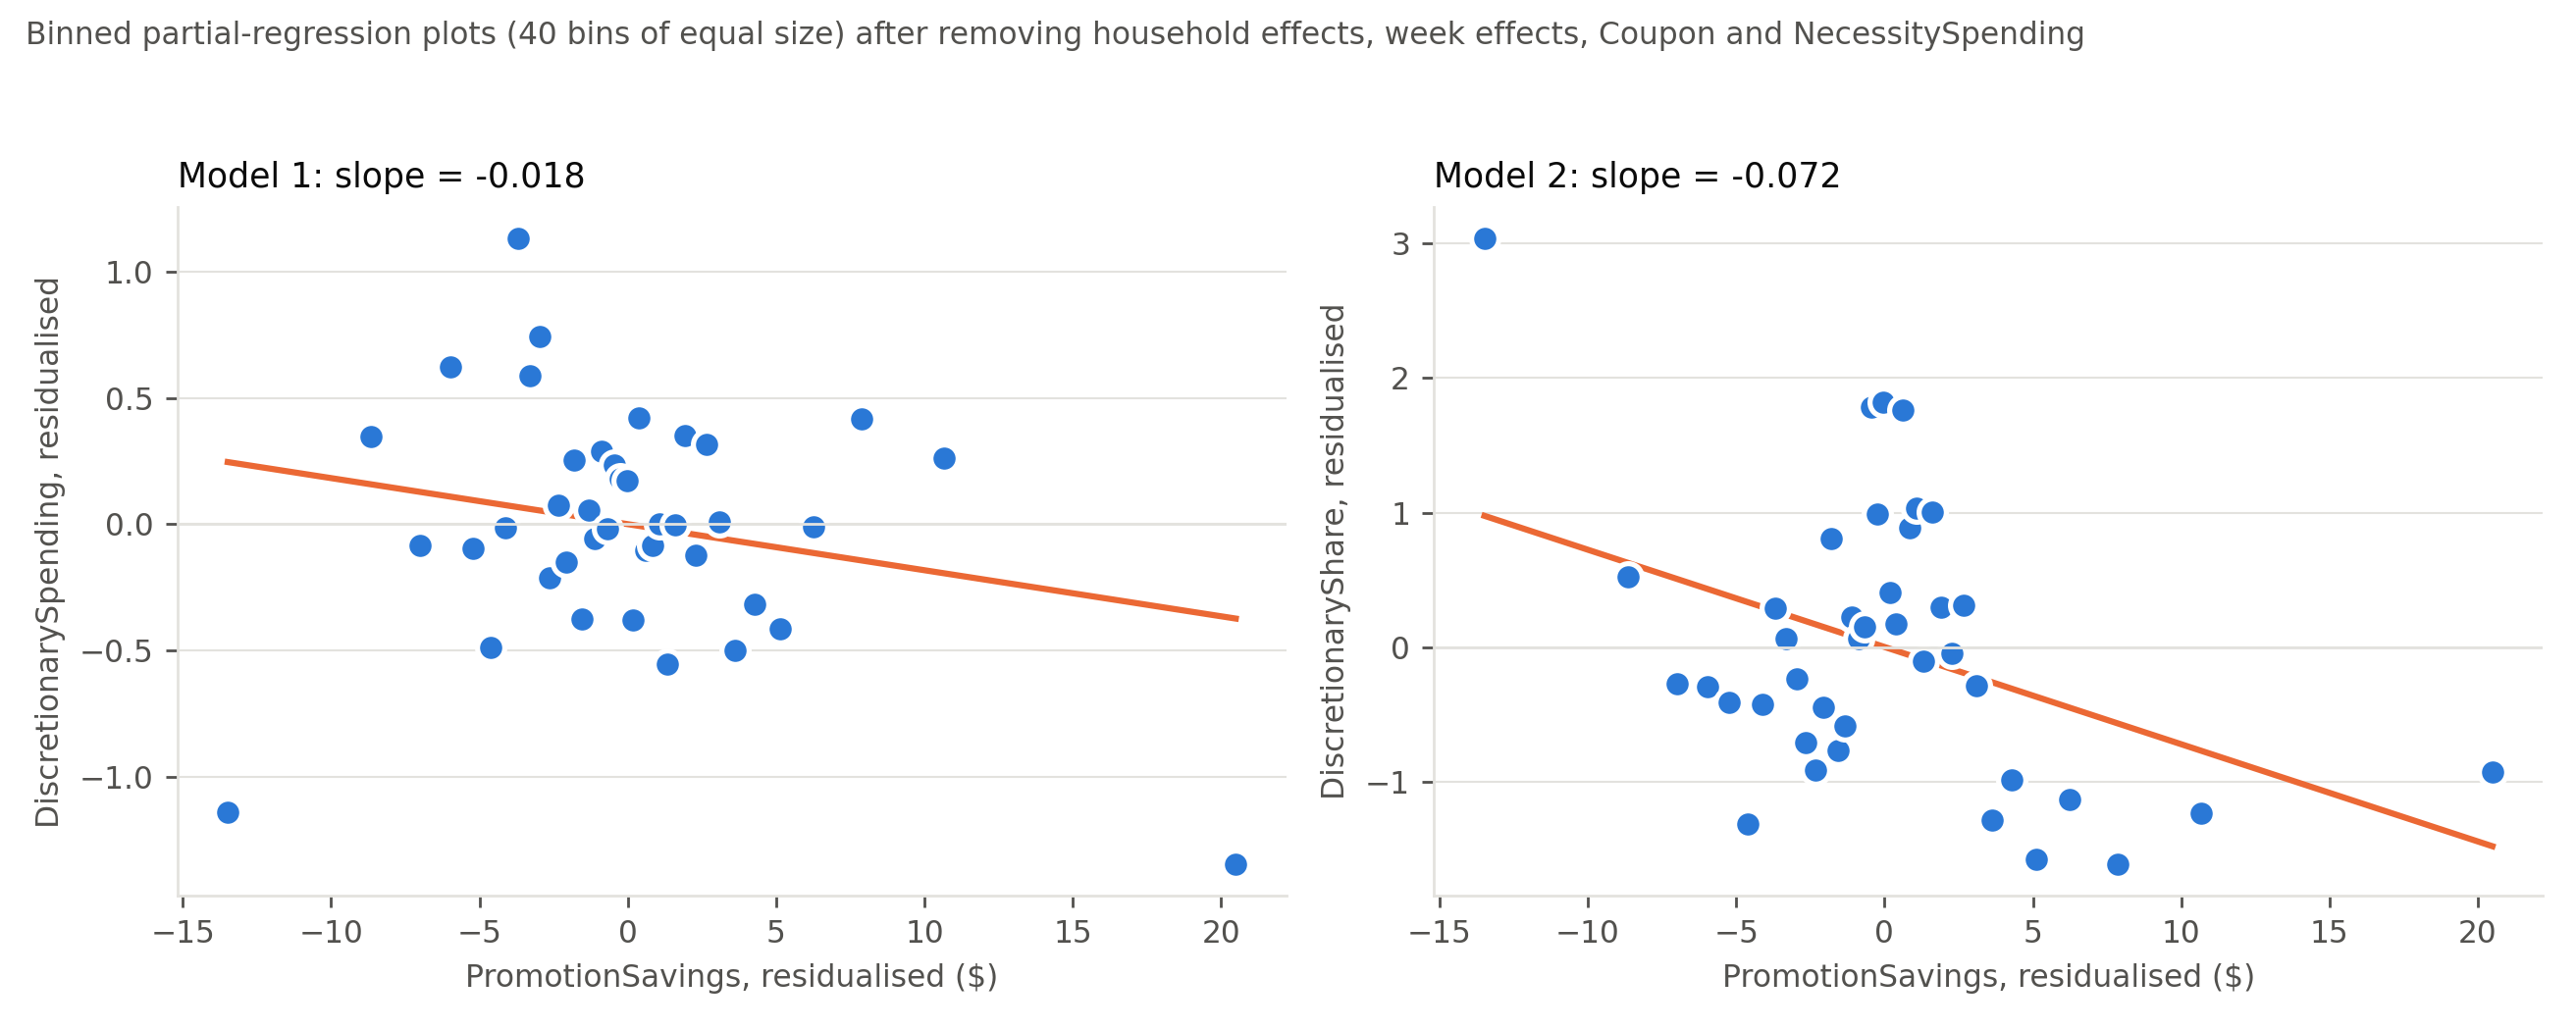

In [9]:
models = b4_models.run(paths)
show_image(paths.out_b / "b4_fig_stability.png", width=900)
show_image(paths.out_b / "b4_fig_binned.png", width=900)

### B5. Robustness, falsification and mechanism checks (Chapter 4.8)

Blocks A to K: build-up, basket-size control, coupon and outcome definitions, alternative samples, placebo and falsification tests, where the money goes, heterogeneity, non-linearity, fractional-response model, and coupons by item category. The forest plot summarises the specifications.

Writes to `part_b_output/`: `b5_tables.xlsx`, `b5_summary.csv`, `b5_fig_robustness.png`, `part_b5_report.txt`.


A. BUILD-UP: from the raw association to the preferred specification (main sample)
Which ingredient removes the positive raw association? Same two outcomes, savings coefficient shown.
                                Specification    Outcome  Variable  Estimate      SE      p      N
                        A1 no controls, no FE disc_spend promo_nec  0.532*** (0.022) <0.001 55,180
                        A1 no controls, no FE disc_spend    coupon  0.473*** (0.126) <0.001 55,180
                                 A2 + week FE disc_spend promo_nec  0.537*** (0.022) <0.001 55,180
                                 A2 + week FE disc_spend    coupon  0.459*** (0.126) <0.001 55,180
                            A3 + household FE disc_spend promo_nec  0.477*** (0.016) <0.001 55,180
                            A3 + household FE disc_spend    coupon  0.459*** (0.084) <0.001 55,180
          A4 two-way FE, no necessity control disc_spend promo_nec  0.483*** (0.016) <0.001 55,180
          A4 two-way FE

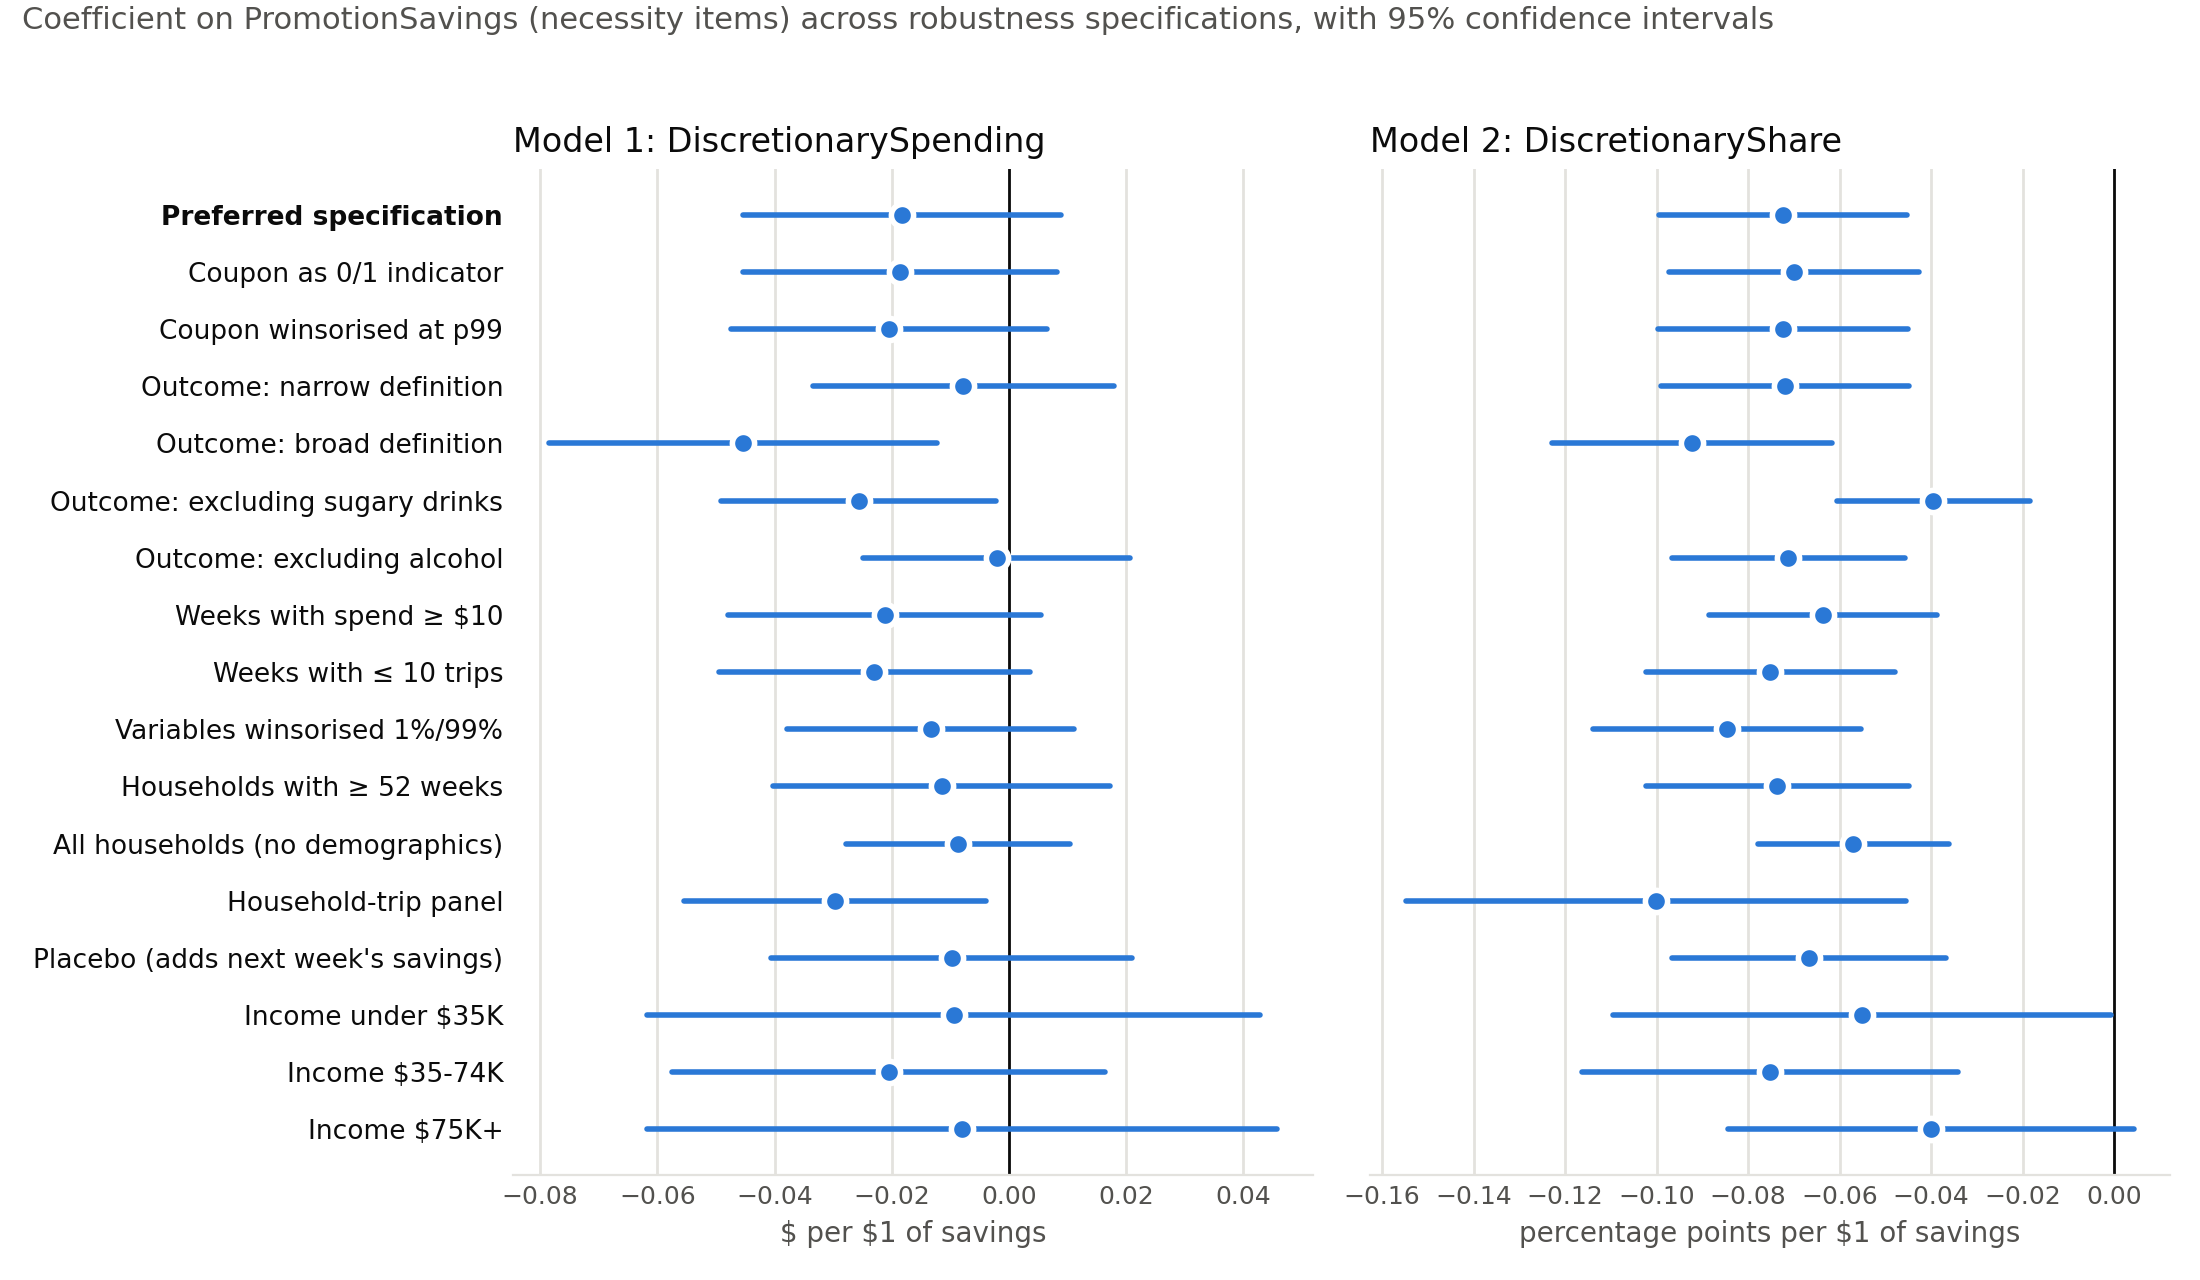

In [10]:
robustness = b5_robustness.run(paths)
b5_forest_figure.run(paths)
show_image(paths.out_b / "b5_fig_robustness.png", width=900)

## Files produced

In [11]:
for folder in (paths.out_a, paths.out_b):
    print(f"{folder.name}/")
    for f in sorted(folder.iterdir()):
        print(f"    {f.name:40s} {f.stat().st_size / 1024:10,.0f} KB")

part_a_output/
    attrition_table.csv                               0 KB
    commodity_mapping_CLASSIFIED.csv                 47 KB
    commodity_mapping_TEMPLATE.csv                   12 KB
    demographics_clean.csv                           50 KB
    household_week_draft.csv                      7,449 KB
    part_a2_report.txt                                8 KB
    part_a_report.txt                                 8 KB
part_b_output/
    attrition_table.csv                               0 KB
    b2_distributions.png                            152 KB
    b3_composition.csv                                1 KB
    b3_correlations.csv                               0 KB
    b3_fig_composition.png                          123 KB
    b3_fig_weekly.png                               325 KB
    b3_household_characteristics.csv                  1 KB
    b3_means_by_group.csv                             1 KB
    b3_summary_stats.csv                              1 KB
    b3_tables.xlsx        